# Model 2 (PullNet): sections 4.2 and 5.2

*Kevin's sections for the group notebook. Same headings as Model 1.*

**Key findings**
1. **PullNet answers 1-hop and 2-hop questions almost perfectly (97.0% and 99.2%), but only 58.5% of 3-hop questions, far below the 91.4% reported in the PullNet paper.**
2. **When it gets a 3-hop question wrong, it has usually found a correct answer but ranked it lower.** In 92% of those mistakes a correct answer was among the entities it collected, most often at rank 2.
3. **Most 3-hop mistakes "stop short".** In 60% of them, the top answer is linked directly to the starting film, such as the film's own star or release year, instead of being 3 steps away. A likely reason is that the model passes information only 2 steps through the graph.
4. **Our re-run of the 3-hop model scored 61.0% (Lily's run: 58.5%).** That is close enough for its mistakes to stand in for hers. Training took just under 2 hours on one GPU.

## 4.2 Model 2: PullNet

**How it works.** PullNet answers a question by exploring the movie knowledge graph (`kb.txt`) step by step, starting from the film in [brackets]:
1. It reads the question and decides which kinds of link look useful, such as director, actor or language.
2. It pulls in up to 10 of those links around the starting film.
3. It picks the 10 most promising entities it has found and pulls in *their* links. It repeats this once per hop.
4. It scores every entity it collected, and the highest score is its answer.

| | |
|---|---|
| **Source** | Lily's implementation of PullNet (Sun et al., 2019), knowledge-base-only and simplified (`pullnet/`, commit `57a08f3`) |
| **Input → output** | A question and its [bracketed] entity go in. A ranked list of entities comes out, and the top one is the answer. Model 1 returns an unordered set instead. |
| **What it learns from** | Only questions and their answers. Unlike Model 1, it is **not told the question type**, so it has to work out which links to follow. |
| **Training** | One model per hop, trained on 20,000 training questions for up to 5 passes (epochs), stopping early once it stops improving. It has 5.9 million learned numbers, mostly one 128-number vector per entity. |
| **Commands** | `python pullnet/train.py --hop N`, then `python pullnet/evaluate_inference.py --hop N --split test` |

*The training settings are the code's defaults, and our re-run used them. Lily's own settings are to be confirmed with her.*

## 5.2 Result 2: PullNet

**What was run**
- **Lily's runs:** one model per hop, each scored on its full test set (9,947 / 14,872 / 14,274 questions). The scores are saved in `pullnet/results/`.
- **Our re-run (3-hop only):** the same code and settings, retrained so we could save the model's answer to **every** test question and look at its mistakes. Lily's scoring script kept only the averages.
- **Two fixes so it would run on our PC (neither changes the model or how it learns):**
  - We restored a function in `pullnet/graph.py` that had been commented out, which made training crash.
  - We ran training through `analysis/pullnet_run/run_with_gpu_cleanup.py`. It frees unused GPU memory after each chunk of 256 questions. Without it, the 8 GB graphics card filled up and each chunk went from about 15 seconds to about 19 minutes.

**How to read the scores**
- **Hits@1:** the model's top answer is one of the correct answers. This is the main score.
- **Hits@10:** a correct answer appears somewhere in the model's top 10.

In [1]:
import json, os, re
from collections import Counter, defaultdict
from pathlib import Path

REPO = Path(os.environ.get("COMP9444_REPO_ROOT", "..")).expanduser().resolve()
METAQA = Path(os.environ.get("METAQA_ROOT", REPO / "MetaQA")).expanduser().resolve()
RUN = REPO / "analysis" / "pullnet_run"

def load_scores(path):
    data = json.loads(Path(path).read_text())
    return {"n": data["n"], **data["results"]["run"]["metrics"]}

lily = {hop: load_scores(REPO / f"pullnet/results/hop{hop}_test_full.json") for hop in (1, 2, 3)}
rerun = load_scores(RUN / "results/hop3_test_full.json")
answers = [json.loads(line) for line in open(RUN / "predictions/hop3_test.jsonl")]
print(f"Loaded Lily's scores for 3 hops, our 3-hop re-run, and {len(answers):,} per-question answers")

Loaded Lily's scores for 3 hops, our 3-hop re-run, and 14,274 per-question answers


### Finding 1: near-perfect on 1-hop and 2-hop, much weaker on 3-hop

In [2]:
def pct(x):  # 1 decimal, but 99.99% must not print as 100.0%
    return f"{100 * x:.2f}%" if 0.9995 <= x < 1 else f"{100 * x:.1f}%"

print(f"{'':7}{'questions':>10}{'top answer correct':>21}{'Hits@1':>9}{'Hits@10':>9}")
for hop, s in lily.items():
    print(f"{hop}-hop  {s['n']:>9,}{round(s['hits@1'] * s['n']):>15,} of {s['n']:<6,}"
          f"{pct(s['hits@1']):>8}{pct(s['hits@10']):>9}")
print("Source: pullnet/results/hop{1,2,3}_test_full.json (Lily's runs)")

        questions   top answer correct   Hits@1  Hits@10
1-hop      9,947          9,650 of 9,947    97.0%   99.99%
2-hop     14,872         14,756 of 14,872   99.2%    99.8%
3-hop     14,274          8,350 of 14,274   58.5%    94.7%
Source: pullnet/results/hop{1,2,3}_test_full.json (Lily's runs)


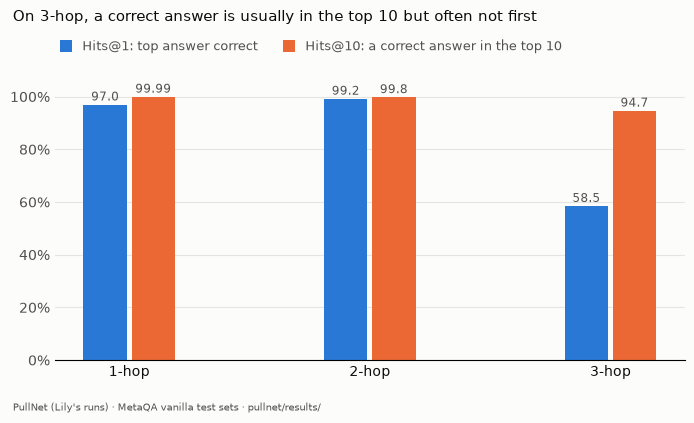

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = [("Hits@1: top answer correct", "hits@1", "#2a78d6"),
          ("Hits@10: a correct answer in the top 10", "hits@10", "#eb6834")]
fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for i, (label, key, color) in enumerate(SERIES):
    xs = [hop - 1 + (i - 0.5) * 0.2 for hop in lily]
    values = [100 * s[key] for s in lily.values()]
    ax.bar(xs, values, width=0.18, color=color, label=label, zorder=2)
    for x, v in zip(xs, values):
        ax.text(x, v + 1.5, pct(v / 100).rstrip("%"), ha="center", fontsize=8.5, color=INK_2)
ax.set_xticks(range(3), ["1-hop", "2-hop", "3-hop"])
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20), [f"{t}%" for t in range(0, 101, 20)])
ax.tick_params(colors=INK_2, length=0)
ax.tick_params(axis="x", colors=INK, labelsize=10)
ax.grid(axis="y", color=GRID, zorder=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.02), ncol=2, frameon=False, fontsize=9,
          labelcolor=INK_2, handlelength=1, handleheight=1)
fig.suptitle("On 3-hop, a correct answer is usually in the top 10 but often not first",
             x=0.02, ha="left", fontsize=11, color=INK, y=0.965)
fig.text(0.02, 0.01, "PullNet (Lily's runs) · MetaQA vanilla test sets · pullnet/results/",
         fontsize=7.5, color=INK_2)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.13, top=0.82)
(REPO / "analysis/figures").mkdir(parents=True, exist_ok=True)
fig.savefig(REPO / "analysis/figures/pullnet_hits_by_hop.png", dpi=200, facecolor=SURFACE)
plt.show()

**What this means:** each extra hop is one more link the model has to get right, and the third hop is where it breaks down.

### Comparison with published results

In [4]:
from IPython.display import Markdown, display

# Hits@1 (%) on MetaQA, knowledge-base-only setting, copied from Sun et al. (2019), Table 2.
# KV-Mem and GRAFT-Net: the PullNet authors' re-implementations (marked * in their table).
# VRN: the number from the VRN paper, as quoted in the same table.
PAPER = [("KV-Mem", "PullNet paper, Table 2 (re-implemented by its authors)", (96.2, 82.7, 48.9)),
         ("VRN", "VRN paper, quoted in PullNet paper Table 2", (97.5, 89.9, 62.5)),
         ("GRAFT-Net", "PullNet paper, Table 2 (re-implemented by its authors)", (97.0, 94.8, 77.7)),
         ("PullNet (paper)", "PullNet paper, Table 2", (97.0, 99.9, 91.4))]
LILY_ROWS = [("Hits@1", "hits@1"), ("MRR (×100)", "mrr"), ("Recall@10", "recall@10"),
             ("Answer coverage", "answer_coverage")]

rows = ["| Model | Score | 1-hop | 2-hop | 3-hop | Source |", "|---|---|---:|---:|---:|---|"]
for name, source, values in PAPER:
    rows.append(f"| {name} | Hits@1 | " + " | ".join(f"{v:.1f}" for v in values) + f" | {source} |")
for i, (label, key) in enumerate(LILY_ROWS):
    name = "**PullNet (Lily's runs)**" if i == 0 else ""
    source = "`pullnet/results/hop{1,2,3}_test_full.json`" if i == 0 else "same files"
    rows.append(f"| {name} | {label} | " + " | ".join(f"{100 * lily[h][key]:.1f}" for h in (1, 2, 3))
                + f" | {source} |")
display(Markdown("\n".join(rows)))

| Model | Score | 1-hop | 2-hop | 3-hop | Source |
|---|---|---:|---:|---:|---|
| KV-Mem | Hits@1 | 96.2 | 82.7 | 48.9 | PullNet paper, Table 2 (re-implemented by its authors) |
| VRN | Hits@1 | 97.5 | 89.9 | 62.5 | VRN paper, quoted in PullNet paper Table 2 |
| GRAFT-Net | Hits@1 | 97.0 | 94.8 | 77.7 | PullNet paper, Table 2 (re-implemented by its authors) |
| PullNet (paper) | Hits@1 | 97.0 | 99.9 | 91.4 | PullNet paper, Table 2 |
| **PullNet (Lily's runs)** | Hits@1 | 97.0 | 99.2 | 58.5 | `pullnet/results/hop{1,2,3}_test_full.json` |
|  | MRR (×100) | 98.3 | 99.5 | 71.9 | same files |
|  | Recall@10 | 99.4 | 92.1 | 57.2 | same files |
|  | Answer coverage | 99.4 | 95.1 | 65.6 | same files |

How to read this table:
- **Only Hits@1 can be compared with the paper**, which reports nothing else for MetaQA. All rows use the knowledge base only, the same setting as Lily's runs.
- **MRR:** 1 ÷ the rank of the first correct answer, averaged over questions (ranked 1st = 1, 2nd = 0.5). Shown ×100.
- **Recall@10:** the share of *all* of a question's correct answers that are in its top 10. Questions with many answers can't reach 100%.
- **Answer coverage:** the share of a question's correct answers that PullNet collected at all, before ranking. Recall@10 can never be higher than this.

**What this means:** on 1-hop and 2-hop, Lily's PullNet is as good as the best published models. On 3-hop it beats KV-Mem (48.9) but falls below VRN (62.5), GRAFT-Net (77.7) and the paper's PullNet (91.4).

### Finding 2: on 3-hop, a correct answer is usually found but ranked below a wrong one

In [5]:
wrong = [a for a in answers if a["hits@1"] == 0]
found = [a for a in wrong if a["gold_retrieved"] > 0]
in_top10 = [a for a in wrong if a["first_correct_rank"] and a["first_correct_rank"] <= 10]
at_rank2 = [a for a in wrong if a["first_correct_rank"] == 2]
print(f"3-hop questions answered wrongly (our re-run): {len(wrong):,} of {len(answers):,}")
print(f"  a correct answer WAS collected, just ranked lower: {len(found):,} ({len(found) / len(wrong):.0%} of the wrong ones)")
print(f"     ...and it was in the top 10:                    {len(in_top10):,} ({len(in_top10) / len(wrong):.0%})")
print(f"     ...and it was ranked 2nd:                       {len(at_rank2):,} ({len(at_rank2) / len(wrong):.0%})")
print(f"  no correct answer was collected at all:            {len(wrong) - len(found):,} ({1 - len(found) / len(wrong):.0%})")
print("Source: analysis/pullnet_run/predictions/hop3_test.jsonl")

3-hop questions answered wrongly (our re-run): 5,569 of 14,274
  a correct answer WAS collected, just ranked lower: 5,141 (92% of the wrong ones)
     ...and it was in the top 10:                    4,866 (87%)
     ...and it was ranked 2nd:                       2,301 (41%)
  no correct answer was collected at all:            428 (8%)
Source: analysis/pullnet_run/predictions/hop3_test.jsonl


**What this means:** the searching part of PullNet mostly works. In 92% of its wrong 3-hop answers, a correct answer had already been collected, and in 41% it was ranked 2nd.
The weak point is the **last step: choosing which collected entity is the answer.**

### Finding 3: most mistakes stop short at the starting film

In [6]:
ROLE_LINK = {"director": "directed_by", "writer": "written_by", "actor": "starred_actors",
             "genre": "has_genre", "language": "in_language", "year": "release_year"}
forward, backward, linked = defaultdict(set), defaultdict(set), defaultdict(set)
for line in open(METAQA / "kb.txt", encoding="utf-8"):
    subject, link, obj = line.rstrip("\n").split("|")
    forward[subject, link].add(obj)
    backward[obj, link].add(subject)
    linked[subject].add(obj)
    linked[obj].add(subject)

def follow(start, middle_role, answer_role):
    # start film -> its middle_role (e.g. director) -> that person's other films -> answer_role
    middle, last = ROLE_LINK[middle_role], ROLE_LINK[answer_role]
    found = set()
    for person in forward[start, middle]:
        for film in backward[person, middle] - {start}:
            found |= forward[film, last] - ({person} if last == middle else set())
    return found

same = sum(follow(a["topic"], *a["qtype"].split("_to_")[1::2]) == set(a["gold"]) for a in answers)
print(f"Check: following each question's path in kb.txt gives exactly MetaQA's correct answers "
      f"for {same:,} of {len(answers):,} questions\n")

REASONS = {  # key: (label, stopped short?)
    "own":    ("the starting film's own answer (e.g. its own star or release year)", True),
    "middle": ("the person the question goes through (e.g. its director)", True),
    "linked": ("something else linked to the starting film", True),
    "never":  ("never collected a correct answer", False),
    "other":  ("other mix-ups", False),
}

def why_wrong(a):
    _, middle_role, _, answer_role = a["qtype"].split("_to_")
    guess, start = a["top10"][0][0], a["topic"]
    if a["gold_retrieved"] == 0:
        return "never"
    if guess in forward[start, ROLE_LINK[middle_role]]:
        return "middle"
    if guess in forward[start, ROLE_LINK[answer_role]]:
        return "own"
    if guess in linked[start]:
        return "linked"
    return "other"

for a in answers:
    a["why_wrong"] = why_wrong(a) if a["hits@1"] == 0 else None
counts = Counter(a["why_wrong"] for a in wrong)

print(f"Why the top answer was wrong ({len(wrong):,} wrong 3-hop answers, our re-run):")
for stopped_short, heading in ((True, "Stopped short: top answer is linked directly to the starting film"),
                               (False, "Other mistakes")):
    keys = [k for k, (_, s) in REASONS.items() if s == stopped_short]
    total = sum(counts[k] for k in keys)
    print(f"  {heading}: {total:,} ({total / len(wrong):.0%})")
    for k in keys:
        print(f"    {counts[k]:>6,}  {counts[k] / len(wrong):>4.0%}  {REASONS[k][0]}")

Check: following each question's path in kb.txt gives exactly MetaQA's correct answers for 14,274 of 14,274 questions

Why the top answer was wrong (5,569 wrong 3-hop answers, our re-run):
  Stopped short: top answer is linked directly to the starting film: 3,331 (60%)
     2,382   43%  the starting film's own answer (e.g. its own star or release year)
       636   11%  the person the question goes through (e.g. its director)
       313    6%  something else linked to the starting film
  Other mistakes: 2,238 (40%)
       428    8%  never collected a correct answer
     1,810   33%  other mix-ups


In [7]:
SHORT = [k for k, (_, s) in REASONS.items() if s]
print(f"{'Asks for':10}{'questions':>10}{'top answer correct':>20}{'mistakes that':>16}{'mistakes that':>16}")
print(f"{'':10}{'':>10}{'':>20}{'stopped short':>16}{'never found':>16}")
by_type = defaultdict(list)
for a in answers:
    by_type[a["qtype"].split("_to_")[3]].append(a)
for kind, group in sorted(by_type.items(), key=lambda kv: sum(a["hits@1"] for a in kv[1]) / len(kv[1])):
    mistakes = [a for a in group if a["hits@1"] == 0]
    short = sum(a["why_wrong"] in SHORT for a in mistakes)
    never = sum(a["why_wrong"] == "never" for a in mistakes)
    print(f"{kind:10}{len(group):>10,}{sum(a['hits@1'] for a in group) / len(group):>19.1%}"
          f"{short / len(mistakes):>16.0%}{never / len(mistakes):>16.0%}")

person = [a for a in wrong if a["qtype"].split("_to_")[3] in ("actor", "director", "writer")]
print(f"\nWhen the answer should be a person (actor, director or writer): "
      f"{sum(a['why_wrong'] in SHORT for a in person) / len(person):.0%} of the mistakes stopped short")
# (only non-empty entries: looking a key up in a defaultdict adds an empty one)
films = {s for (s, link), objs in forward.items() if objs and link in ROLE_LINK.values()}
with_language = {s for (s, link), objs in forward.items() if objs and link == "in_language"}
print(f"Films in kb.txt with a language listed: {len(with_language):,} of {len(films):,} ({len(with_language) / len(films):.0%})")

Asks for   questions  top answer correct   mistakes that   mistakes that
                                           stopped short     never found
actor          1,942              30.8%             87%              4%
writer         2,333              53.9%             76%              2%
director       2,083              56.2%             85%              1%
year           3,064              61.3%             31%              1%
language       1,824              68.0%              9%             57%
genre          3,028              84.5%             34%              2%

When the answer should be a person (actor, director or writer): 83% of the mistakes stopped short
Films in kb.txt with a language listed: 3,090 of 16,427 (19%)


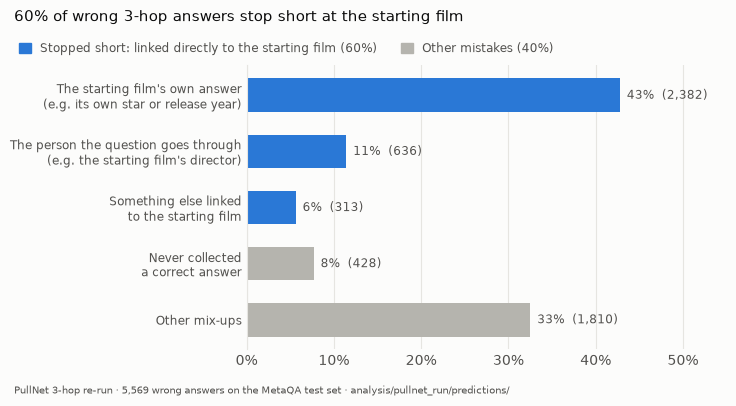

In [8]:
ROWS = ["own", "middle", "linked", "never", "other"]
LABELS = {"own": "The starting film's own answer\n(e.g. its own star or release year)",
          "middle": "The person the question goes through\n(e.g. the starting film's director)",
          "linked": "Something else linked\nto the starting film",
          "never": "Never collected\na correct answer",
          "other": "Other mix-ups"}
SHORT_COLOR, OTHER_COLOR = "#2a78d6", "#b5b4ae"
short_total = sum(counts[k] for k in SHORT)

fig, ax = plt.subplots(figsize=(7.5, 4.0), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ys = list(range(len(ROWS)))[::-1]
for y, key in zip(ys, ROWS):
    share = 100 * counts[key] / len(wrong)
    ax.barh(y, share, height=0.6, zorder=2, color=SHORT_COLOR if key in SHORT else OTHER_COLOR)
    ax.text(share + 0.8, y, f"{share:.0f}%  ({counts[key]:,})", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(ys, [LABELS[k] for k in ROWS], fontsize=8.5, color=INK)
ax.set_xlim(0, 55)
ax.set_xticks(range(0, 51, 10), [f"{t}%" for t in range(0, 51, 10)])
ax.tick_params(colors=INK_2, length=0)
ax.grid(axis="x", color=GRID, zorder=0)
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)
handles = [plt.Rectangle((0, 0), 1, 1, color=SHORT_COLOR), plt.Rectangle((0, 0), 1, 1, color=OTHER_COLOR)]
fig.legend(handles, [f"Stopped short: linked directly to the starting film ({100 * short_total / len(wrong):.0f}%)",
                     f"Other mistakes ({100 - 100 * short_total / len(wrong):.0f}%)"],
           loc="upper left", bbox_to_anchor=(0.012, 0.915), ncol=2, frameon=False, fontsize=8.5,
           labelcolor=INK_2, handlelength=1, handleheight=1)
fig.suptitle(f"{100 * short_total / len(wrong):.0f}% of wrong 3-hop answers stop short at the starting film",
             x=0.02, ha="left", fontsize=11, color=INK, y=0.97)
fig.text(0.02, 0.01, f"PullNet 3-hop re-run · {len(wrong):,} wrong answers on the MetaQA test set · "
         "analysis/pullnet_run/predictions/", fontsize=7.5, color=INK_2)
fig.subplots_adjust(left=0.33, right=0.97, bottom=0.12, top=0.83)
fig.savefig(REPO / "analysis/figures/pullnet_3hop_mistakes.png", dpi=200, facecolor=SURFACE)
plt.show()

How each wrong top answer was sorted, using `kb.txt`:
- **The starting film's own answer:** e.g. the question asks for the stars of other films *by the same director as* [X], and the model gave a star of [X] itself.
- **The person the question goes through:** e.g. it gave the director of [X], when the question asked for the actors in that director's other films.
- **Something else linked to the starting film:** any other entity one step from [X].
- **Never collected a correct answer:** none of the correct answers was among the entities it collected.
- **Other mix-ups:** everything else, e.g. a year or genre of some other nearby film.

**What this means:** a 3-hop answer is three steps from the starting film. In most of its mistakes the model picks something only **one** step away. This is worst when the answer is a person: for questions asking for actors, only 31% are right, and 87% of the mistakes stopped short. Language questions are different. Their mistakes are mostly "never collected", because only 19% of films in `kb.txt` have a language listed, so the path to the answer often runs through one particular film (see example 3).

**Likely reason (not tested):** Lily's graph network passes information **2 steps** (`NUM_MESSAGE_ROUNDS = 2` in `pullnet/config.py`; her comment in `pullnet/message_passing.py` says one round reaches direct neighbours only). The "this is the starting film" marker therefore reaches entities 1 and 2 steps away, but never the 3-step answers. The model can tell what is *near* the start, but not what is exactly 3 steps away. Retraining with `--rounds 3` would test this.

### Real examples (our 3-hop re-run)

In [9]:
EXAMPLE_LINES = {1711: ["Robert Zemeckis", "Thomas F. Wilson"],      # line -> entities worth checking
                 3230: ["Tony Gilroy", "2002", "2007"],
                 10544: ["Steven Spielberg", "The Goonies", "Spanish"]}
traces = {t["line"]: t for t in json.loads((RUN / "results/hop3_example_traces.json").read_text())}

for line in EXAMPLE_LINES:
    a = answers[line - 1]
    print(f"3-hop/vanilla/qa_test.txt, line {a['line']}  ({a['qtype']})")
    print(f"  Question:        {a['question']}")
    print(f"  Correct answers: {', '.join(a['gold'][:6])}" + (f" (+{len(a['gold']) - 6} more)" if len(a['gold']) > 6 else ""))
    print(f"  PullNet's top 3: {', '.join(name for name, _ in a['top10'][:3])}")
    print(f"  First correct answer at rank: {a['first_correct_rank']}")
    print(f"  Sorted as: {REASONS[a['why_wrong']][0]}")
    steps = traces[line]["explore_steps"]
    print(f"  Entities explored at steps 2 and 3: " +
          ", ".join(f"{s['num_selected']} of {s['num_candidates']} found" for s in steps))
    print("  Collected by PullNet: " + ", ".join(
        f"{name} {'yes' if traces[line]['collected'][name] else 'no'}"
        for name in EXAMPLE_LINES[line]))
    print()
print("Sources: analysis/pullnet_run/predictions/hop3_test.jsonl, analysis/pullnet_run/results/hop3_example_traces.json")

3-hop/vanilla/qa_test.txt, line 1711  (movie_to_director_to_movie_to_actor)
  Question:        who starred movies for the director of [I Wanna Hold Your Hand]
  Correct answers: Patrick Stewart, Jim Carrey, Lea Thompson, David Morse, Eddie Deezen, Sally Field (+32 more)
  PullNet's top 3: Robert Zemeckis, Thomas F. Wilson, Michael J. Fox
  First correct answer at rank: 2
  Sorted as: the person the question goes through (e.g. its director)
  Entities explored at steps 2 and 3: 9 of 9 found, 10 of 52 found
  Collected by PullNet: Robert Zemeckis yes, Thomas F. Wilson yes

3-hop/vanilla/qa_test.txt, line 3230  (movie_to_writer_to_movie_to_year)
  Question:        when did the movies release whose writers also wrote [The Bourne Identity]
  Correct answers: 1992, 1983, 2000, 1985, 2007, 2004 (+2 more)
  PullNet's top 3: 2002, 1995, 2007
  First correct answer at rank: 3
  Sorted as: the starting film's own answer (e.g. its own star or release year)
  Entities explored at steps 2 and 3: 10 

**Example 1, line 1711: gave the person the question goes through**
- *Observed:* the question asks for actors in other films by the director of [I Wanna Hold Your Hand]. The top answer, Robert Zemeckis, is that director (`I Wanna Hold Your Hand|directed_by|Robert Zemeckis` in `kb.txt`). He is not listed as an actor in any film. A correct answer, Thomas F. Wilson, was ranked 2nd.
- *Likely why:* Zemeckis is one step from the starting film and closely tied to it. The model picked him instead of following his films one more step to their actors.

**Example 2, line 3230: gave the starting film's own answer**
- *Observed:* the question asks for the release years of other films by the writers of [The Bourne Identity]. The top answer, 2002, is the year of *The Bourne Identity* itself (`The Bourne Identity|release_year|2002`), and none of its writers' other films came out that year. A correct answer, 2007, was ranked 3rd.
- *Likely why:* the starting film's own year is one step away, so it gets the strongest signal from the "starting film" marker.

**Example 3, line 10544: never collected a correct answer**
- *Observed:* the question asks for the languages of other films written by the writer of [Close Encounters of the Third Kind], Steven Spielberg. In `kb.txt`, only one of his other films, *The Goonies*, has a language listed (Spanish). PullNet collected *The Goonies*, but on the last step it explored only 10 of the 62 entities it had found, and it never pulled in that film's language. Its top answer was Russian.
- *Likely why:* the limit of 10 entities explored per step (`TOP_K_PULL_NODES = 10` in `pullnet/config.py`). When one specific film is the only route to the answer, missing it means no correct answer at all.

### Re-run check and training cost

In [10]:
log = (RUN / "logs/train_hop3.log").read_text()
epochs = re.findall(r"Train loss: ([0-9.]+).*\n.*Dev\s+loss: ([0-9.]+)", log)
wall = re.search(r"Elapsed \(wall clock\) time \(h:mm:ss or m:ss\): (\S+)", log).group(1)
params = int(re.search(r"Trainable parameters: (\d+)", log).group(1))
size_mb = (RUN / "checkpoints/hop_3_best.pt").stat().st_size / 1e6

print(f"3-hop Hits@1:  Lily's run {pct(lily[3]['hits@1'])}  |  our re-run {pct(rerun['hits@1'])}")
print(f"3-hop Hits@10: Lily's run {pct(lily[3]['hits@10'])}  |  our re-run {pct(rerun['hits@10'])}")
print(f"Training time: {wall} (h:mm:ss) on one RTX 2070 SUPER, {len(epochs)} epochs")
print(f"Model size:    {params:,} learned numbers, {size_mb:.0f} MB file")
print("Loss per epoch (lower is better):")
for i, (train_loss, dev_loss) in enumerate(epochs, start=1):
    print(f"  epoch {i}: training {float(train_loss):.3f}   dev {float(dev_loss):.3f}")
print("Sources: analysis/pullnet_run/results/hop3_test_full.json, analysis/pullnet_run/logs/train_hop3.log")

3-hop Hits@1:  Lily's run 58.5%  |  our re-run 61.0%
3-hop Hits@10: Lily's run 94.7%  |  our re-run 95.1%
Training time: 1:55:39 (h:mm:ss) on one RTX 2070 SUPER, 5 epochs
Model size:    5,942,170 learned numbers, 71 MB file
Loss per epoch (lower is better):
  epoch 1: training 1.110   dev 1.002
  epoch 2: training 0.973   dev 0.951
  epoch 3: training 0.894   dev 0.891
  epoch 4: training 0.831   dev 0.844
  epoch 5: training 0.787   dev 0.803
Sources: analysis/pullnet_run/results/hop3_test_full.json, analysis/pullnet_run/logs/train_hop3.log


**What this means:** our re-run scored a little higher than Lily's run (61.0% vs 58.5% top answer correct, and 95.1% vs 94.7% in the top 10). We don't know the exact cause: her settings are unconfirmed, and GPU training doesn't repeat exactly. Both runs show the same pattern, so the mistakes above represent her model. The dev loss was still falling at epoch 5, so more training might help a little.

### Why Lily's 3-hop score is below the paper's

In [11]:
import random
from collections import deque

# Lily's training draws its "wrong answer" examples at random, one per correct answer, from every
# entity within 3 steps of the starting film (pullnet/training_data.py). How often does that include
# an entity directly linked to the starting film, i.e. the kind of mistake in Finding 3?
train = []
for line in open(METAQA / "3-hop/vanilla/qa_train.txt", encoding="utf-8"):
    question, gold = line.rstrip("\n").split("\t")
    train.append((re.search(r"\[(.+?)\]", question).group(1), set(gold.split("|"))))
random.Random(42).shuffle(train)    # the same shuffle train.py uses for its 20,000-question subsample
sample = train[:1000]               # the first 1,000 of those 20,000

pool_sizes, chance_any = [], []
for start, gold in sample:
    steps, queue = {start: 0}, deque([start])
    while queue:                    # every entity within 3 steps, as in pullnet/supervision.py
        node = queue.popleft()
        if steps[node] < 3:
            for nxt in linked[node]:
                if nxt not in steps:
                    steps[nxt] = steps[node] + 1
                    queue.append(nxt)
    pool = [e for e in steps if e not in gold]
    near = sum(steps[e] == 1 for e in pool)
    n_wrong = min(len(pool), sum(g in steps for g in gold))
    p_none = 1.0                    # chance that none of the n_wrong random picks is 1 step away
    for i in range(n_wrong):
        p_none *= (len(pool) - near - i) / (len(pool) - i)
    pool_sizes.append(len(pool))
    chance_any.append(1 - p_none)

print(f"Training questions checked: {len(sample):,} (the first 1,000 of train.py's 20,000)")
print(f"  entities the wrong-answer examples are drawn from: median {sorted(pool_sizes)[len(sample) // 2]:,} per question")
print(f"  chance that a question's wrong-answer examples include anything directly linked to the starting film: "
      f"{sum(chance_any) / len(sample):.1%} on average")
print("Sources: MetaQA/3-hop/vanilla/qa_train.txt, kb.txt, sampling rule in pullnet/training_data.py")

Training questions checked: 1,000 (the first 1,000 of train.py's 20,000)
  entities the wrong-answer examples are drawn from: median 10,798 per question
  chance that a question's wrong-answer examples include anything directly linked to the starting film: 1.9% on average
Sources: MetaQA/3-hop/vanilla/qa_train.txt, kb.txt, sampling rule in pullnet/training_data.py


Lily's model matches the paper on 1-hop (97.0 vs 97.0) and almost matches it on 2-hop (99.2 vs 99.9), but on 3-hop it scores 58.5 against 91.4. Her result files show that the gap is mostly in ranking, not searching: a correct answer is in the top 10 for 94.7% of 3-hop questions but ranked first for only 58.5%. The code and logs point to four differences, none of which we tested on its own.
(1) The graph network is simplified. Lily's comment in `pullnet/message_passing.py` calls it "not the exact GRAFT-Net/PullNet graph convolution". It passes information only 2 steps (`NUM_MESSAGE_ROUNDS = 2`, a setting her comment says was "added for 2-hop questions"), one step short of where a 3-hop answer sits.
(2) Training rarely shows the model the mistakes it actually makes. Its wrong-answer examples are drawn at random, one per correct answer, from every entity within 3 steps (`pullnet/training_data.py`), a median of 10,798 entities per question. So on average only 1.9% of training questions include even one entity directly linked to the starting film as a wrong answer. Yet 60% of its 3-hop test mistakes are exactly such entities (Finding 3).
(3) It trains and tests on differently built graphs. Training graphs are built from the correct paths (teacher forcing in `pullnet/training.py`), with up to 20 extra links per entity. Test graphs come from the model's own choices: 10 links per entity and 10 entities per step (`pullnet/config.py`, also recorded in her result files).
(4) It sees a fraction of the data. The code's defaults, which the header of `pullnet/train.py` gives as the "real run", train on 20,000 of the 114,196 training questions for 5 epochs. In our re-run, the dev loss was still falling at the last epoch (1.002 → 0.803, `analysis/pullnet_run/logs/train_hop3.log`).
Our re-run scored 61.0%, so the shortfall is not a one-off of Lily's run.

### Limitations
- **The mistakes come from our re-run, not Lily's exact model**, because her trained model files were not available. The re-run used the same code and default settings, and its scores are compared with hers above.
- **Only 3-hop was retrained**, so there is no mistake analysis for 1-hop and 2-hop. They get only 3.0% and 0.8% of questions wrong.
- **The "stopped short" reason is a likely explanation, not a tested one.** Retraining with 3 message-passing rounds (`--rounds 3`, about 2 hours) would test it.
- **Default settings, one run.** The model trains on 20,000 of the 114,196 training questions, and we did not repeat the run with different random seeds.
- **Not in the same column as Model 1.** Model 1 is scored on exact answer sets, which is a stricter score than Hits@1 (see 5.3).

**References**
- Sun, H., Bedrax-Weiss, T., & Cohen, W. W. (2019). PullNet: Open Domain Question Answering with Iterative Retrieval on Knowledge Bases and Text. EMNLP-IJCNLP. arXiv:1904.09537.
- Miller, A., Fisch, A., Dodge, J., Karimi, A.-H., Bordes, A., & Weston, J. (2016). Key-Value Memory Networks for Directly Reading Documents. EMNLP. (KV-Mem)
- Sun, H., Dhingra, B., Zaheer, M., Mazaitis, K., Salakhutdinov, R., & Cohen, W. W. (2018). Open Domain Question Answering Using Early Fusion of Knowledge Bases and Text. EMNLP. (GRAFT-Net)
- Zhang, Y., Dai, H., Kozareva, Z., Smola, A. J., & Song, L. (2018). Variational Reasoning for Question Answering with Knowledge Graph. AAAI. (VRN; also introduced MetaQA)